# The AMP-BLOSUM metric: construction, and does it change what MutAnG generates?

Reference notebook for the AMP-BLOSUM substitution matrix and the positive-definite
*metric* matrix derived from it. Written to be read top-to-bottom. §1, §2 and §4 run
on CPU from files in this repository. §3 loads HydrAMP and needs a GPU; the output
of that call is saved in the notebook.

**What this notebook covers**

1. §1 — the AMP-BLOSUM matrix, displayed next to NCBI BLOSUM62.
2. §2 — how the metric matrix is built from it, and why the construction is guaranteed
   to be positive definite (no magic involved).
3. §3 — invoking MutAnG with that metric for a single parent.
4. §4 — comparing the mutant populations produced with and without the metric.

**Headline result, so you can decide whether to read on.** The construction works and is
exact. But on 2,152 parents the metric-arm mutants are *not* more similar to their
parent than the unmodified arm's are: the mean per-residue AMP-BLOSUM similarity is
0.260 in both arms. §2 shows the mechanism that explains it — at the exponent used
(`beta = 4`), the construction transmits the matrix diagonal and discards almost all
of its pair structure, so the sampler is reweighted by *which residue is introduced*
rather than by *which substitution* is made.


## Setup

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def _repository_root(start: Path) -> Path:
    """Walk upward from `start` to the directory containing `pyproject.toml`.

    Kernel working directories vary by IDE/session, so paths below are anchored to
    the repository root rather than to the notebook location.
    """
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError(f"no pyproject.toml at or above {start}")


REPO = _repository_root(Path.cwd())
MATRICES = REPO / "src/pep_compass/optimization/components/helpers/substitution_matrices/matrices"
ANALYSIS = REPO / "assets/experiments/analysis/blosum_distance"
print(f"repository root: {REPO}")

repository root: /home/pszmk/Projects/pep-compass


## §1 The AMP-BLOSUM matrix

`AMPBLOSUM62_float.txt` is an AMP-specific substitution matrix generated by
`assets/scripts/blosum_matrix/generate_ampblosum62.py`. It is shipped alongside the
NCBI `BLOSUM62.txt` in the same directory.

The residue order below is the matrix file's own header order, `ARNDCQEGHILKMFPSTWYV`
— **not** alphabetical. Every array in this notebook is indexed in that order, and
mixing it with an alphabetical ordering silently transposes the matrix into a
different one.

In [2]:
ALPHABET = list("ARNDCQEGHILKMFPSTWYV")


def load_matrix(path: Path) -> pd.DataFrame:
    """Read a whitespace-delimited substitution matrix into a residue x residue frame."""
    header, rows = None, {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if not line.strip() or line.lstrip().startswith("#"):
            continue
        parts = line.split()
        if header is None:
            header = parts
            continue
        rows[parts[0]] = [float(v) for v in parts[1:]]
    frame = pd.DataFrame(rows, index=header).T
    return frame.loc[ALPHABET, ALPHABET]


amp = load_matrix(MATRICES / "AMPBLOSUM62_float.txt")
b62 = load_matrix(MATRICES / "BLOSUM62.txt")
print(f"header order in file: {''.join(amp.columns)}")
amp.round(2)

header order in file: ARNDCQEGHILKMFPSTWYV


,A,R,N,D,C,Q,E,G,H,I,L,K,M,F,P,S,T,W,Y,V
A,0.27,-0.14,0.01,0.07,0.09,0.09,0.21,0.04,-0.18,-0.00,-0.07,-0.07,0.13,-0.04,0.14,0.06,0.12,-0.44,0.11,0.20
R,-0.14,0.10,0.00,0.06,0.05,-0.06,-0.00,-0.08,0.05,-0.05,0.04,0.07,-0.03,0.04,-0.07,-0.10,-0.16,0.15,0.04,-0.15
N,0.01,0.00,0.16,-0.18,0.21,0.15,0.02,-0.01,0.23,0.03,-0.03,-0.01,-0.11,-0.13,0.22,-0.11,0.18,-0.12,-0.01,-0.11
D,0.07,0.06,-0.18,1.02,-0.45,-0.26,0.27,0.03,-0.06,-0.24,-0.20,0.05,0.36,0.16,-0.22,0.46,0.23,-0.05,-0.16,-0.09
C,0.09,0.05,0.21,-0.45,1.10,0.18,0.12,-0.22,0.30,-0.11,0.01,0.06,-0.15,-0.19,0.05,-0.23,-0.11,-0.26,0.08,-0.15
Q,0.09,-0.06,0.15,-0.26,0.18,0.06,0.15,-0.02,0.34,-0.05,-0.08,0.01,0.08,-0.20,0.16,0.09,0.12,-0.06,-0.01,0.02
E,0.21,-0.00,0.02,0.27,0.12,0.15,0.59,0.17,0.14,-0.29,-0.19,-0.10,-0.04,0.01,0.13,0.23,0.19,-0.44,0.15,0.13
G,0.04,-0.08,-0.01,0.03,-0.22,-0.02,0.17,0.62,0.04,-0.19,-0.24,-0.03,-0.05,0.37,0.06,0.17,-0.04,-0.28,-0.24,-0.15
H,-0.18,0.05,0.23,-0.06,0.30,0.34,0.14,0.04,0.35,-0.10,-0.09,0.10,-0.02,-0.21,0.14,-0.07,-0.07,0.10,0.12,-0.21
I,-0.00,-0.05,0.03,-0.24,-0.11,-0.05,-0.29,-0.19,-0.10,0.20,0.17,-0.10,-0.01,0.04,-0.07,-0.14,-0.07,0.11,0.06,0.14


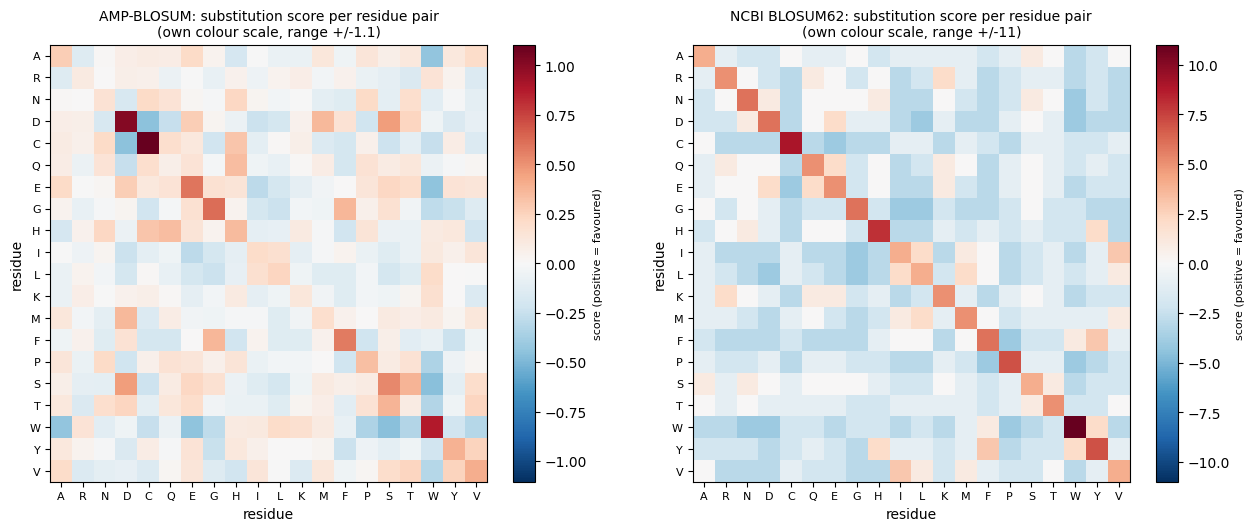

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
# each panel gets its own symmetric scale: the two matrices differ ~10-fold in range,
# so a shared colour axis would render the AMP matrix as uniformly blank
for ax, (name, frame) in zip(axes, [("AMP-BLOSUM", amp), ("NCBI BLOSUM62", b62)]):
    v = np.abs(frame.to_numpy()).max()
    im = ax.imshow(frame.to_numpy(), cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_xticks(range(20), ALPHABET, fontsize=8)
    ax.set_yticks(range(20), ALPHABET, fontsize=8)
    ax.set_title(f"{name}: substitution score per residue pair\n(own colour scale, range +/-{v:.3g})", fontsize=10)
    ax.set_xlabel("residue")
    ax.set_ylabel("residue")
    fig.colorbar(im, ax=ax, fraction=0.046).set_label("score (positive = favoured)", fontsize=8)
fig.tight_layout()

In [4]:
# The two matrices sit on different scales, and agree only weakly on which pairs are favoured.
pair = pd.DataFrame({
    "statistic": ["mean diagonal (self-score)", "mean off-diagonal", "min", "max"],
    "AMP-BLOSUM": [np.diag(amp).mean(), amp.to_numpy()[~np.eye(20, dtype=bool)].mean(),
                   amp.to_numpy().min(), amp.to_numpy().max()],
    "NCBI BLOSUM62": [np.diag(b62).mean(), b62.to_numpy()[~np.eye(20, dtype=bool)].mean(),
                      b62.to_numpy().min(), b62.to_numpy().max()],
})
iu = np.triu_indices(20, k=1)
correlation = stats.pearsonr(amp.to_numpy()[iu], b62.to_numpy()[iu])[0]
print(f"correlation across the 190 distinct residue pairs: r = {correlation:+.3f}")
pair.round(3)

correlation across the 190 distinct residue pairs: r = +0.287


,statistic,AMP-BLOSUM,NCBI BLOSUM62
0,mean diagonal (self-score),0.411,5.800
1,mean off-diagonal,-0.010,-1.426
2,min,-0.459,-4.000
3,max,1.105,11.000


## §2 From substitution matrix to metric matrix

A metric (an inner product on residue space) must be a **positive semi-definite**
matrix. A substitution matrix is not one: it is symmetric, but it has negative
eigenvalues, so `x @ S @ x` can be negative and `S` cannot define a squared length.

The construction below turns `S` into a metric in two steps, and neither is magic —
each is a standard fact with a one-line justification.

**Step 1 — diagonal shift.** Adding `c * I` shifts every eigenvalue up by `c`. Choosing
`c = -lambda_min` makes the smallest eigenvalue exactly zero, so `S + cI` is positive
semi-definite by construction. This changes only self-scores (the diagonal); every
*pair* score is untouched.

**Step 2 — elementwise exponential.** `K = exp(beta * (S + cI))`, applied entrywise, is
again positive semi-definite. The reason is the Schur product theorem: the entrywise
product of two PSD matrices is PSD, hence every entrywise power of a PSD matrix is
PSD, and `exp` is a convergent sum of those powers with non-negative coefficients.
`beta` controls how sharply score differences are amplified.

The result `K` is a Gram matrix: `K[i, j]` is an inner product between residues `i`
and `j`, large when the pair is favoured. That is the object used as the ambient
metric.

In [5]:
S = amp.to_numpy().copy()
assert np.allclose(S, S.T), "substitution matrix must be symmetric"

eigenvalues = np.linalg.eigvalsh(S)
print(f"eigenvalues of S span [{eigenvalues.min():+.3f}, {eigenvalues.max():+.3f}]")
print(f"S is positive semi-definite: {eigenvalues.min() >= 0}  <- this is the problem")

eigenvalues of S span [-0.397, +2.473]
S is positive semi-definite: False  <- this is the problem


In [6]:
BETA = 4.0          # exponent used by the metric arm compared in §4
EPSILON = 1e-9      # nudge the zero eigenvalue strictly positive

shift = -eigenvalues.min() + EPSILON
S_shifted = S + shift * np.eye(len(ALPHABET))
print(f"diagonal shift c = {shift:.4f}")
print(f"min eigenvalue after shift: {np.linalg.eigvalsh(S_shifted).min():.2e}")

K = np.exp(BETA * S_shifted)
K_eigenvalues = np.linalg.eigvalsh(K)
print(f"min eigenvalue of K = exp(beta * (S + cI)): {K_eigenvalues.min():.3e}")
assert K_eigenvalues.min() > 0, "K must be positive definite"
print("K is a valid metric (positive definite).")

diagonal shift c = 0.3974
min eigenvalue after shift: 1.00e-09
min eigenvalue of K = exp(beta * (S + cI)): 4.392e+00
K is a valid metric (positive definite).


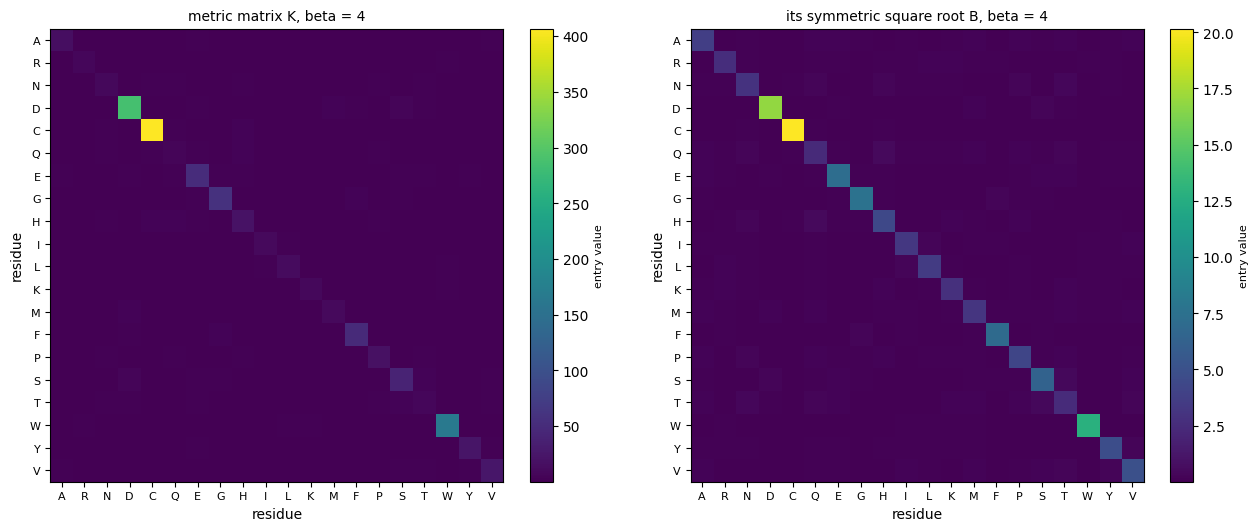

In [7]:
# The metric matrix, and the matrix square root used to apply it as a change of basis.
K_eigenvalues_full, eigenvectors = np.linalg.eigh(K)
B = (eigenvectors * np.sqrt(np.clip(K_eigenvalues_full, 0.0, None))) @ eigenvectors.T
assert np.allclose(B @ B, K, atol=1e-6), "B must satisfy B @ B == K"

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, (name, matrix, cmap) in zip(
    axes,
    [("metric matrix K", K, "viridis"), ("its symmetric square root B", B, "viridis")],
):
    im = ax.imshow(matrix, cmap=cmap)
    ax.set_xticks(range(20), ALPHABET, fontsize=8)
    ax.set_yticks(range(20), ALPHABET, fontsize=8)
    ax.set_title(f"{name}, beta = {BETA:g}", fontsize=10)
    ax.set_xlabel("residue")
    ax.set_ylabel("residue")
    fig.colorbar(im, ax=ax, fraction=0.046).set_label("entry value", fontsize=8)
fig.tight_layout()

### What the metric actually transmits

The two heatmaps above are the whole story of §4's negative result, so they are worth
reading carefully rather than admiring.

`K` is dominated by its diagonal. Because `exp` amplifies score differences
multiplicatively, and self-scores are the largest entries of any substitution matrix,
the diagonal of `K` is driven far apart while off-diagonal entries are pressed towards
each other, down to a small fraction of the mean diagonal entry. The square root `B` inherits this: it is close to a diagonal
matrix, meaning the change of basis it induces mostly **rescales each residue
coordinate independently** rather than mixing residues according to how
interchangeable the matrix says they are.

The consequence for generation: a sampler moving through a space warped by `K` feels
*which residue it is moving toward* (a column effect, set by self-scores) much more
strongly than *which substitution it is making* (the pair structure that the matrix
was built to encode). The numbers below quantify that.

In [8]:
diagonal = np.diag(K)
off_diagonal = K[~np.eye(20, dtype=bool)]
row_mass_on_diagonal = np.abs(np.diag(B)) / np.abs(B).sum(axis=1)

print(f"K diagonal spans [{diagonal.min():.3g}, {diagonal.max():.3g}] "
      f"-- a factor of {diagonal.max() / diagonal.min():.3g}")
print(f"K off-diagonal mean: {off_diagonal.mean():.3g} "
      f"({off_diagonal.mean() / diagonal.mean():.2%} of the mean diagonal entry)")
print(f"share of each row of B carried by its diagonal entry: "
      f"{row_mass_on_diagonal.min():.1%} to {row_mass_on_diagonal.max():.1%} "
      f"(median {np.median(row_mass_on_diagonal):.1%})")

K diagonal spans [6.35, 407] -- a factor of 64.1
K off-diagonal mean: 1.18 (1.92% of the mean diagonal entry)
share of each row of B carried by its diagonal entry: 45.9% to 96.2% (median 67.7%)


In [9]:
# How beta trades off the two channels. Small beta keeps pair structure; large beta
# collapses the metric onto the diagonal (and, in the limit, onto a uniform rescaling).
sweep = []
for beta in [0.25, 0.5, 1.0, 2.0, 4.0, 8.0]:
    K_beta = np.exp(beta * S_shifted)
    B_beta_eigenvalues, B_beta_vectors = np.linalg.eigh(K_beta)
    B_beta = (B_beta_vectors * np.sqrt(np.clip(B_beta_eigenvalues, 0.0, None))) @ B_beta_vectors.T
    sweep.append({
        "beta": beta,
        "diagonal_max_over_min": np.diag(K_beta).max() / np.diag(K_beta).min(),
        "offdiag_over_diag": K_beta[~np.eye(20, dtype=bool)].mean() / np.diag(K_beta).mean(),
        "median_diagonal_share_of_B": float(np.median(np.abs(np.diag(B_beta)) / np.abs(B_beta).sum(axis=1))),
    })
pd.DataFrame(sweep).round(4)

,beta,diagonal_max_over_min,offdiag_over_diag,median_diagonal_share_of_B
0,0.25,1.2969,0.8132,0.1394
1,0.50,1.6820,0.6584,0.1829
2,1.00,2.8292,0.4253,0.2565
3,2.00,8.0046,0.1660,0.3968
4,4.00,64.0733,0.0192,0.6765
5,8.00,4105.3899,0.0001,0.9567


## §3 Invoking MutAnG with the metric for one parent

The metric is not a config key inside `src/`. The call that generated the metric arm
is the in-process patch sitting next to this notebook, taken from the Claude Science
session on anton (`kernel_gram.py`, `kernel_ambient_metric.py`).

`kernel_gram.py` builds `K = exp(beta * (S + cI))` and lifts it onto the decoder
alphabet. `kernel_ambient_metric.install` monkey-patches
`pep_compass.autoencoder.geometry.compute_tangent_decomposition`, so the decoder
Jacobian is decomposed under that metric. Nothing under `src/` is edited.

Two details that are easy to get wrong from §1. The heatmap there is in NCBI order,
`ARNDCQEGHILKMFPSTWYV`. HydrAMP's tokens are ` ACDEFGHIKLMNPQRSTVWY`, with the
padding symbol at index 0. `read_score_matrix` reorders the same file into that
alphabet before the patch sees it.

The call below is one parent, `FLYKWWIRIGRLKL`, run twice: unpatched, then with
`beta = 4`. The stages are the neighbourhood config's MutAnG stages — direction
threshold `1e-3` with at least 5 directions, token threshold `0.1`, at most 256
candidates — and sequences are kept at Hamming distance 1–4. There is no SORBES
walk and no APEX score. That walk, over 2,152 parents, is §4.


In [10]:
# Token block in the decoder's own order. Padding is index 0 and stays Euclidean.
import sys
sys.path.insert(0, str(ANALYSIS))
import kernel_gram as kg

PARENT = "FLYKWWIRIGRLKL"          # a dbaasp seed peptide, 14 residues
bundle = kg.build_gram(MATRICES / "AMPBLOSUM62_float.txt", beta=BETA)
token_block = bundle["token_block"]

print(f"parent: {PARENT} ({len(PARENT)} residues)")
print(f"HydrAMP token order: {kg.PADDED_ALPHABET!r}")
print(f"shift c = {bundle['shift']:.4f}; min eigenvalue of K = {bundle['min_eigenvalue']:.3f}")
print(f"token block {token_block.shape}; padding uncoupled: "
      f"{token_block[0, 0] == 1.0 and np.all(token_block[0, 1:] == 0.0)}")


parent: FLYKWWIRIGRLKL (14 residues)
HydrAMP token order: ' ACDEFGHIKLMNPQRSTVWY'
shift c = 0.3974; min eigenvalue of K = 4.392
token block (21, 21); padding uncoupled: True


In [11]:
# One parent, unmodified MutAnG and the same call with the metric installed.
import numpy as np
import torch
import kernel_ambient_metric as kam
from pep_compass.autoencoder import geometry as geometry_module
from pep_compass.autoencoder.factory import AutoencoderFactory
from pep_compass.optimization.components.mutation_generators.strategies.mutang.combination.baseline import (
    BaselineCombination,
)
from pep_compass.optimization.components.mutation_generators.strategies.mutang.direction_selection.baseline import (
    BaselineDirectionSelection,
)
from pep_compass.optimization.components.mutation_generators.strategies.mutang.mutation_selection.threshold import (
    ThresholdSelection,
)
from pep_compass.optimization.components.mutation_generators.strategies.mutang.scoring.max_absolute_loading import (
    MaxAbsoluteLoading,
)

MATRIX_PATH = str(MATRICES / "AMPBLOSUM62_float.txt")
SCORE_MATRIX = kg.read_score_matrix(MATRIX_PATH)
RESIDUE_INDEX = {residue: position for position, residue in enumerate(kg.AMINO_ACIDS)}


def _device() -> str:
    if not torch.cuda.is_available():
        return "cpu"
    free = [torch.cuda.mem_get_info(index)[0] for index in range(torch.cuda.device_count())]
    return f"cuda:{int(np.argmax(free))}"


def mutang_once(autoencoder, parent: str, **install_kwargs) -> pd.DataFrame:
    """Return Hamming 1-4 mutants of `parent` from one MutAnG proposal pass."""
    handle = kam.install(matrix_path=MATRIX_PATH, **install_kwargs)
    try:
        directions = BaselineDirectionSelection(threshold=1e-3, minimum=5)
        scoring = MaxAbsoluteLoading(max_len=kam.MAX_LEN, alphabet_size=kam.ALPHABET_SIZE)
        selection = ThresholdSelection(threshold=0.1)
        combination = BaselineCombination(kg.PADDED_ALPHABET, maximum_candidates=256)
        with torch.no_grad():
            latents = autoencoder.encode_peptides([parent])
            decomposition = geometry_module.compute_tangent_decomposition(autoencoder, latents)
        singular = decomposition.singular_values[0]
        left = decomposition.left_vectors[0]
        options = selection.select(scoring.score(left, directions.select(singular)), len(parent))
        rows = []
        for sequence in combination.generate(parent, options, np.random.default_rng(0)):
            if sequence == parent:
                continue
            distance = sum(left_aa != right_aa for left_aa, right_aa in zip(parent, sequence))
            if not 1 <= distance <= 4:
                continue
            score = sum(
                SCORE_MATRIX[RESIDUE_INDEX[left_aa], RESIDUE_INDEX[right_aa]]
                for left_aa, right_aa in zip(parent, sequence)
            )
            rows.append({
                "sequence": sequence,
                "hamming_distance": distance,
                "amp_blosum_score": score,
                "amp_per_residue": score / len(parent),
            })
        patch = handle.summary()
    finally:
        handle.uninstall()
    frame = pd.DataFrame(rows)
    frame.attrs["n_options"] = len(options)
    frame.attrs["patch"] = patch
    return frame


DEVICE = _device()
autoencoder = AutoencoderFactory.build(
    "hydramp",
    model="article_25",
    device=DEVICE,
    jacobian_mode="approx",
    jacobian_eps=0.05,
    field_eps=0.05,
)
vanilla_one = mutang_once(autoencoder, PARENT, enable_metric=False)
metric_one = mutang_once(
    autoencoder, PARENT, enable_metric=True, correct_acceleration=True, beta=BETA,
)

print(f"device: {DEVICE}")
print(f"unpatched: {len(vanilla_one)} mutants from {vanilla_one.attrs['n_options']} options, "
      f"mean per-residue similarity {vanilla_one.amp_per_residue.mean():.5f}")
print(f"metric:    {len(metric_one)} mutants from {metric_one.attrs['n_options']} options, "
      f"mean per-residue similarity {metric_one.amp_per_residue.mean():.5f}")
print(f"shared sequences: {len(set(vanilla_one.sequence) & set(metric_one.sequence))}")
print("patch:", metric_one.attrs["patch"]["metric"])
metric_one.sort_values(["hamming_distance", "sequence"]).reset_index(drop=True)


device: cuda:2
unpatched: 60 mutants from 12 options, mean per-residue similarity 0.30258
metric:    5 mutants from 5 options, mean per-residue similarity 0.32576
shared sequences: 5
patch: entrywise exp(beta*(S+cI)) on AMPBLOSUM62_float.txt, beta=4.0, c=0.3973843694


,sequence,hamming_distance,amp_blosum_score,amp_per_residue
0,FLYKWWFRIGRLKL,1,4.738153,0.338440
1,FLYKWWIRPGRLKL,1,4.628128,0.330581
2,FLYKWWPRIGRLKL,1,4.628128,0.330581
3,FLYKWWFRPGRLKL,2,4.459457,0.318533
4,FLYKWWPRPGRLKL,2,4.349432,0.310674


## §4 Unmodified MutAnG vs metric MutAnG

The comparison the specification asks for, in its own order:

1. For each parent, take the two mutant populations and score every mutant against its
   parent with the AMP-BLOSUM similarity.
2. Compare the two score populations — means first, then a test.
3. Aggregate over parents two ways: the share of parents on which the metric arm wins,
   and a paired test across parents.

Two details that change the answer and are worth stating before the numbers.

**Similarity is normalised per residue.** `amp_blosum_score` is a sum over positions, so
it grows with peptide length; dividing by length makes parents comparable. Within a
single parent this is a constant factor and changes nothing.

**Mutation count is a confounder.** More substitutions means lower similarity, so any
difference in how far the two arms wander shows up as a similarity difference that has
nothing to do with substitution preference. The specification's own fallback — restrict
to single-substitution mutants — removes it, and is reported alongside the pooled result.

In [12]:
VANILLA = REPO / "results/blosum_distance/mutang_apex_neighborhood_dbaasp/neighborhood_scores.csv"
METRIC = REPO / "results/blosum_distance/mutang_apex_neighborhood_dbaasp_metric_kernel/neighborhood_scores.csv"
SUMMARY = ANALYSIS / "blosum_metric_parent_comparison.csv"

COLUMNS = ["parent", "length", "hamming_distance", "amp_blosum_score"]


def load_arm(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path, usecols=COLUMNS)
    frame = frame[frame.hamming_distance.between(1, 4)].copy()
    frame["amp_per_residue"] = frame.amp_blosum_score / frame.length
    return frame


recomputed = VANILLA.exists() and METRIC.exists()
print(f"raw result directories present: {recomputed}")
if not recomputed:
    print(f"falling back to the committed per-parent summary: {SUMMARY.name}")
    print("(`results/` is gitignored, so this section reads the committed per-parent summary)")

raw result directories present: False
falling back to the committed per-parent summary: blosum_metric_parent_comparison.csv
(`results/` is gitignored, so this section reads the committed per-parent summary)


In [13]:
def build_summary(vanilla: pd.DataFrame, metric: pd.DataFrame) -> pd.DataFrame:
    """Per-parent comparison of the two arms, for both mutation-count subsets.

    This is the code that produced the committed summary CSV.
    """
    by_parent_vanilla = {p: g for p, g in vanilla.groupby("parent", observed=True)}
    by_parent_metric = {p: g for p, g in metric.groupby("parent", observed=True)}
    shared = sorted(set(by_parent_vanilla) & set(by_parent_metric))

    rows = []
    for subset, single_only in [("all_mutants_H1_4", False), ("hamming_distance_1_only", True)]:
        for parent in shared:
            x, y = by_parent_vanilla[parent], by_parent_metric[parent]
            if single_only:
                x = x[x.hamming_distance == 1]
                y = y[y.hamming_distance == 1]
            if len(x) < 5 or len(y) < 5:
                continue
            rows.append({
                "subset": subset,
                "parent": parent,
                "length": int(x.length.iloc[0]),
                "n_vanilla": len(x),
                "n_metric": len(y),
                "mean_score_vanilla": x.amp_blosum_score.mean(),
                "mean_score_metric": y.amp_blosum_score.mean(),
                "mean_per_residue_vanilla": x.amp_per_residue.mean(),
                "mean_per_residue_metric": y.amp_per_residue.mean(),
                "mannwhitney_p": stats.mannwhitneyu(
                    y.amp_per_residue, x.amp_per_residue, alternative="two-sided"
                ).pvalue,
            })
    return pd.DataFrame(rows)


if recomputed:
    summary = build_summary(load_arm(VANILLA), load_arm(METRIC))
else:
    summary = pd.read_csv(SUMMARY)

print(f"{summary.parent.nunique()} parents compared")
summary.head(3)

2152 parents compared


,subset,parent,length,n_vanilla,n_metric,mean_score_vanilla,mean_score_metric,mean_per_residue_vanilla,mean_per_residue_metric,mannwhitney_p
0,all_mutants_H1_4,AAARLRLLLYLITRR,15,17,38,2.6819,2.3094,0.17879,0.15396,4.665721e-05
1,all_mutants_H1_4,AAHCIALRKGYK,12,23,18,3.6874,2.8837,0.30728,0.24030,4.258100e-07
2,all_mutants_H1_4,AAHCIQLGKR,10,307,51,2.4315,2.4088,0.24315,0.24088,7.335223e-01


In [14]:
# Step 2-3: aggregate over parents, both ways the specification asks for.
aggregate = []
for subset, group in summary.groupby("subset"):
    metric_higher = group.mean_per_residue_metric > group.mean_per_residue_vanilla
    significant = group.mannwhitney_p < 0.05
    paired = stats.wilcoxon(group.mean_per_residue_metric, group.mean_per_residue_vanilla)
    aggregate.append({
        "subset": subset,
        "parents": len(group),
        "mean_similarity_vanilla": group.mean_per_residue_vanilla.mean(),
        "mean_similarity_metric": group.mean_per_residue_metric.mean(),
        "share_parents_metric_higher": metric_higher.mean(),
        "share_significantly_higher": (significant & metric_higher).mean(),
        "share_significantly_lower": (significant & ~metric_higher).mean(),
        "median_difference": (group.mean_per_residue_metric - group.mean_per_residue_vanilla).median(),
        "paired_wilcoxon_p": paired.pvalue,
    })
pd.DataFrame(aggregate).set_index("subset").T.round(5)

subset,all_mutants_H1_4,hamming_distance_1_only
parents,2152.00000,684.00000
mean_similarity_vanilla,0.26047,0.29998
mean_similarity_metric,0.25976,0.29952
share_parents_metric_higher,0.48002,0.46345
share_significantly_higher,0.30204,0.00877
share_significantly_lower,0.34433,0.01316
median_difference,-0.00004,-0.00023
paired_wilcoxon_p,0.20067,0.02831


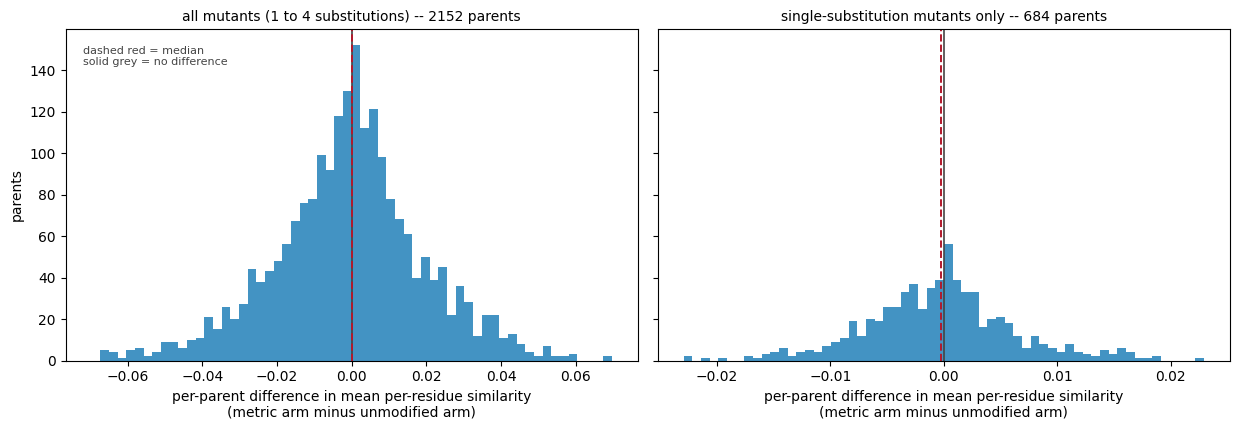

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
for ax, (subset, group) in zip(axes, summary.groupby("subset")):
    difference = group.mean_per_residue_metric - group.mean_per_residue_vanilla
    limit = np.abs(difference).quantile(0.99)
    ax.hist(difference, bins=60, range=(-limit, limit), color="#4393c3", edgecolor="none")
    ax.axvline(0.0, color="#444444", lw=1.2)
    ax.axvline(difference.median(), color="#b2182b", lw=1.4, ls="--")
    label = {"all_mutants_H1_4": "all mutants (1 to 4 substitutions)",
             "hamming_distance_1_only": "single-substitution mutants only"}[subset]
    ax.set_title(f"{label} -- {len(group)} parents", fontsize=10)
    ax.set_xlabel("per-parent difference in mean per-residue similarity\n(metric arm minus unmodified arm)")
axes[0].set_ylabel("parents")
axes[0].text(0.03, 0.95, "dashed red = median\nsolid grey = no difference",
             transform=axes[0].transAxes, va="top", fontsize=8, color="#444444")
fig.tight_layout()

### Reading the table

**The metric arm does not produce more parent-similar mutants.** Mean per-residue
similarity is 0.260 in both arms over 2,152 parents; the median per-parent difference is
-0.00004, i.e. zero to four decimal places and pointing the wrong way. The metric arm is
higher on 48% of parents — a coin flip.

**The naive aggregation is informative precisely because it is symmetric.** The metric
arm is *significantly* higher on 30% of parents and *significantly lower* on 34%. With
thousands of mutants per parent, per-parent tests are powerful enough to call tiny
differences significant in whichever direction noise happens to fall; splitting evenly
in both directions is what no real effect looks like. A result consistent with the
hypothesis would put nearly all significant parents on one side.

**Restricting to single substitutions does not rescue it, and illustrates the gap
between significance and effect size.** On 684 parents the paired Wilcoxon returns
p = 0.028 — nominally significant, and *negative*: the metric arm is slightly less
similar. The median difference is -0.0002 on a quantity whose mean is 0.300, a relative
effect of less than a tenth of a percent. It is a real but negligible difference in the
opposite direction to the one predicted.

## §5 Conclusions

**On "why do we want this metric".** The stated motivation — cheaper, more
biologically plausible substitutions — is testable, and §4 is the test. As wired here,
the metric does not deliver it: mutants generated under the AMP-BLOSUM metric are no
more parent-similar than mutants from the unmodified generator.

**Why not, mechanically.** §2 is the explanation, and it is a property of the
construction rather than of the matrix. Exponentiating a score matrix into a Gram
matrix puts the self-scores on the diagonal, where `exp` drives them far apart, while
compressing the pair structure into near-uniform off-diagonals. The square root applied to the latent basis is then close
to diagonal, so the sampler is reweighted by which residue it introduces, not by which
substitution it makes — and substitution preference is the thing the matrix exists to
encode. The `beta` sweep in §2 shows the trade-off: the pair channel is open only at
small `beta`, and `beta = 4` is well into the regime where it is shut.

**What this does not show.** Three honest limits. The result covers one exponent and
one insertion point; small-`beta` configurations are untested. The metric is applied
as an ambient geometry, not as a substitution proposal — inserting the same matrix
directly into MutAnG's candidate-selection step is a different and untested route.
And §4 measures parent-similarity, not synthesisability or plausibility; if the goal
is plausibility, that needs its own measurement rather than similarity as a proxy.

**Suggested next step.** §3 is that ambient-metric route for one parent, installed
as a monkey-patch rather than as an optimizer component. Before promoting it into
`src/`, re-run the `beta` sweep end to end and check whether a small-`beta`
configuration moves the §4 numbers at all. If it does not, the ambient-metric route
is closed and the proposal-level route is the one worth building.